## Librerías a usar
---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import uniform, kstest
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.sandbox.stats.runs import runstest_1samp

## Generador de números aleatorios
---

In [5]:
# ==========================================
# 1. DEFINICIÓN DEL GENERADOR CONGRUENCIAL LINEAL (LCG)
# ==========================================
def gen(x0, m, a, c, n):
    """
    Genera n números pseudoaleatorios usando el método LCG.
    Fórmula: x_{k+1} = (a * x_k + c) % m
    Devuelve una lista de números en el intervalo [0, 1).
    """
    x = x0
    u = x / m  # Normalizamos el primer valor
    l = [u]    # Lista que almacenará los números generados
    
    # Generamos los n-1 números restantes
    for i in range(n - 1):
        x = (a * x + c) % m  # Aplicamos la recurrencia
        u = x / m            # Normalizamos dividiendo entre m
        l.append(u)
        
    return l

# ==========================================
# 2. PARÁMETROS Y GENERACIÓN DE DATOS
# ==========================================
# Parámetros definidos en tu clase
m = 7787
a = 757
c = 126
x0 = 652
n = 10000  # Número de simulaciones

# Llamamos al generador>
datos = gen(x0, m, a, c, n)

## Pruebas estadísticas
---

In [6]:
# ==========================================
# 3. PRUEBAS ESTADÍSTICAS
# ==========================================

print("--- 1. Prueba de Bondad de Ajuste (Kolmogorov-Smirnov) ---")
# Primero, ajustamos una distribución uniforme a los datos para estimar sus parámetros (loc, scale)
parametros = uniform.fit(datos)
print(f"Parámetros ajustados (loc, scale): {parametros}")

# Realizamos la prueba KS comparando los datos con una distribución uniforme
# H0: Los datos siguen una distribución uniforme.
# Si el p-valor es > 0.05, no rechazamos H0 (los datos son uniformes).
resultado_ks = kstest(datos, 'uniform', args=parametros)
print(f"Estadístico KS: {resultado_ks.statistic:.4f}")
print(f"p-valor: {resultado_ks.pvalue:.5e}")
if resultado_ks.pvalue > 0.05:
    print("Conclusión: No se rechaza la hipótesis de uniformidad")
else:
    print("Conclusión: Se rechaza la hipótesis de uniformidad.")
print("-" * 50)


print("\n--- 2. Prueba de Rachas (Runs Test) ---")
# Esta prueba evalúa la aleatoriedad basándose en la secuencia de valores por encima o debajo de la media.
# H0: La secuencia es aleatoria (independiente).
resultado_rachas = runstest_1samp(datos, cutoff='mean', correction=False)
print(f"Estadístico Z: {resultado_rachas[0]:.4f}")
print(f"p-valor: {resultado_rachas[1]:.5e}")
if resultado_rachas[1] > 0.05:
    print("Conclusión: No se rechaza la aleatoriedad (las rachas son las esperadas).")
else:
    print("Conclusión: Se rechaza la aleatoriedad (hay patrones ocultos).")
print("-" * 50)


print("\n--- 3. Prueba de Autocorrelación (Ljung-Box) ---")
# Evalúa si los valores están correlacionados con sus versiones pasadas (rezagos o lags).
# H0: No hay autocorrelación en los primeros 5 rezagos.
resultado_autocorr = acorr_ljungbox(datos, lags=[1, 2, 3, 4, 5], return_df=True)
print(resultado_autocorr)
print("\nInterpretación: Si los p-valores (lb_pvalue) son > 0.05, no hay evidencia de autocorrelación.")
print("-" * 50)

--- 1. Prueba de Bondad de Ajuste (Kolmogorov-Smirnov) ---
Parámetros ajustados (loc, scale): (0.020290227301913447, 0.9732888146911519)
Estadístico KS: 0.1079
p-valor: 6.95989e-102
Conclusión: Se rechaza la hipótesis de uniformidad.
--------------------------------------------------

--- 2. Prueba de Rachas (Runs Test) ---
Estadístico Z: 13.1738
p-valor: 1.24137e-39
Conclusión: Se rechaza la aleatoriedad (hay patrones ocultos).
--------------------------------------------------

--- 3. Prueba de Autocorrelación (Ljung-Box) ---
       lb_stat      lb_pvalue
1   721.327751  6.885616e-159
2   724.249280  5.386009e-158
3   782.153695  3.210876e-169
4  1282.327436  2.258297e-276
5  1283.455132  2.452809e-275

Interpretación: Si los p-valores (lb_pvalue) son > 0.05, no hay evidencia de autocorrelación.
--------------------------------------------------


## Gráfico
---

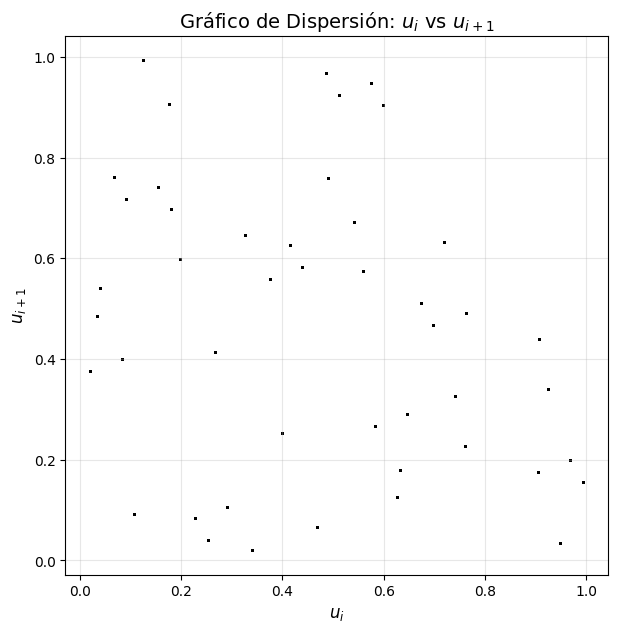

In [7]:
# ==========================================
# 4. GRÁFICO DE DISPERSIÓN (Test Visual de Independencia)
# ==========================================
# En las imágenes se grafica u_i vs u_{i+1} para ver si hay patrones geométricos.
# Si el generador es bueno, debe verse como una nube de puntos aleatoria sin forma.
lx = []
ly = []

for i in range(n - 1):
    lx.append(datos[i])      # Valor actual
    ly.append(datos[i + 1])  # Valor siguiente

plt.figure(figsize=(7, 7))
plt.scatter(lx, ly, s=1, color='black', alpha=0.5)
plt.title('Gráfico de Dispersión: $u_i$ vs $u_{i+1}$', fontsize=14)
plt.xlabel('$u_i$', fontsize=12)
plt.ylabel('$u_{i+1}$', fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()